In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Sales Analytics, in this project i'm working on adding time-series analysis, categorical comparison, calculated metrics, and annotations

# Inspection & Boiler plate

In [32]:
df = pd.read_csv("ecommerce_sales_real_world_practice.csv")
df["Date"] = pd.to_datetime(df["Date"])

df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             24 non-null     datetime64[us]
 1   Product          24 non-null     str           
 2   Category         24 non-null     str           
 3   Units_Sold       24 non-null     int64         
 4   Unit_Price_USD   24 non-null     int64         
 5   Revenue_USD      24 non-null     int64         
 6   Region           24 non-null     str           
 7   Customer_Rating  24 non-null     float64       
 8   Returned_Units   24 non-null     int64         
dtypes: datetime64[us](1), float64(1), int64(4), str(3)
memory usage: 1.8 KB


,Date,Units_Sold,Unit_Price_USD,Revenue_USD,Customer_Rating,Returned_Units
count,24,24.000000,24.000000,24.000000,24.000000,24.000000
mean,2026-03-30 00:00:00,31.458333,469.791667,12611.458333,4.429167,1.500000
min,2026-01-05 00:00:00,12.000000,100.000000,3100.000000,4.000000,1.000000
25%,2026-02-14 06:00:00,23.750000,100.000000,4475.000000,4.275000,1.000000
50%,2026-03-30 00:00:00,30.500000,375.000000,8250.000000,4.450000,1.000000
75%,2026-05-12 18:00:00,40.250000,700.000000,21000.000000,4.600000,2.000000
max,2026-06-22 00:00:00,52.000000,1000.000000,30000.000000,4.800000,3.000000
std,NaN,10.794440,357.905985,9427.921584,0.225503,0.589768


# Monthly Revenue Trend

Goal: How did the company's revenue change month by month

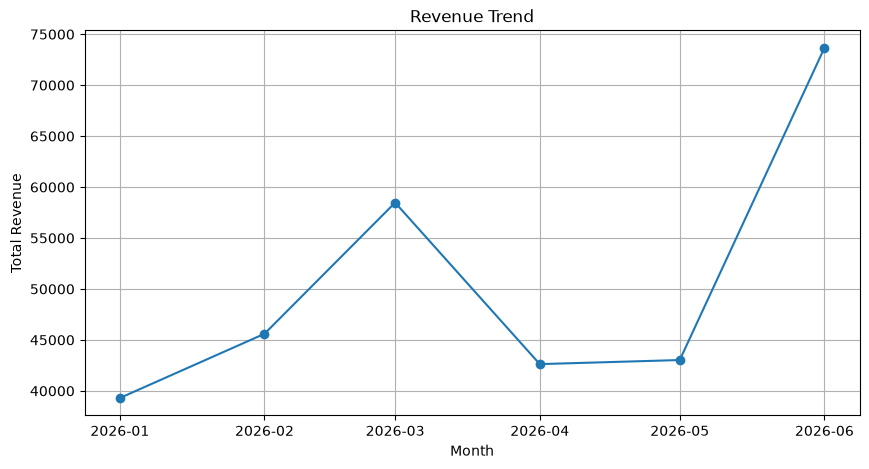

In [33]:
monthtly_revenue = (df.groupby(df["Date"].dt.to_period("M"))["Revenue_USD"].sum())
                    
plt.figure(figsize=(10, 5))
plt.plot(monthtly_revenue.index.to_timestamp(),
         monthtly_revenue.values,
          marker="o")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.title("Revenue Trend")
plt.grid()


# Best Product by Region

Goal: which product generated the most revenue in each region?

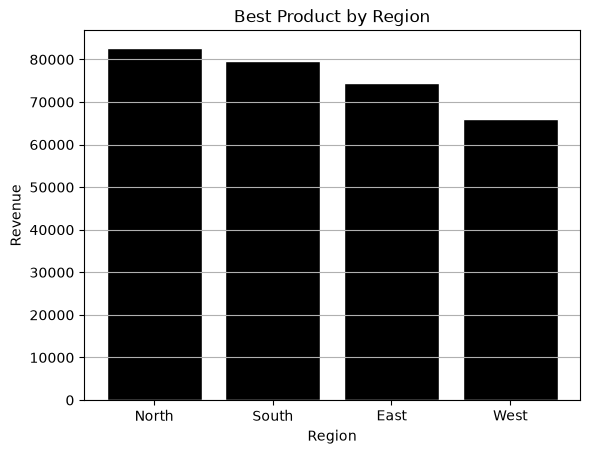

In [34]:
product_by_region = df.groupby("Region").agg({
    "Product": "sum",
    "Revenue_USD": "sum"
})
idx = product_by_region.groupby("Region")["Revenue_USD"].idxmax()
top_product = product_by_region.sort_values("Revenue_USD", ascending=False)

plt.bar(top_product.index,
        top_product["Revenue_USD"],
        color="black",
        edgecolor="white")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.title("Best Product by Region")
plt.grid(axis='y')

plt.show()

# Return Rate Investigation

Goal: which product has the highest return rate

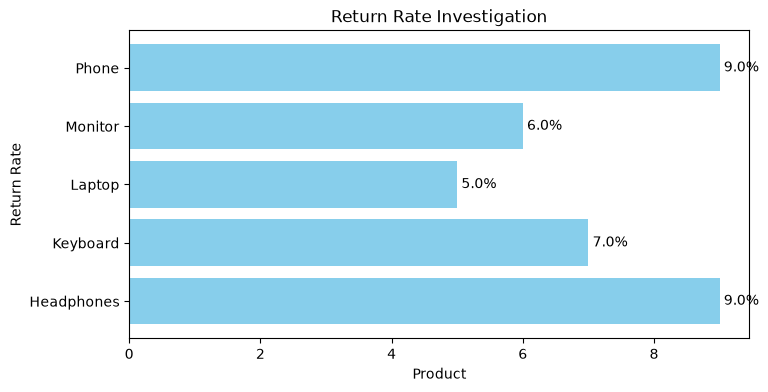

In [35]:
summary = df.groupby("Product").agg({
    "Units_Sold": "sum",
    "Returned_Units": "sum"
})
returns = df.groupby("Product")["Returned_Units"].sum()
summary["Return_Rate"] = (summary["Returned_Units"] / summary["Units_Sold"] * 100)

plt.figure(figsize=(8, 4))
bar = plt.barh(returns.index,
        returns.values,
        color="skyblue")
plt.bar_label(bar, fmt="%1.1f%%", padding=3)
plt.xlabel("Product")
plt.ylabel("Return Rate")
plt.title("Return Rate Investigation")


plt.show()


# Revenue vs Customer Rating

Goal: Do products with higher customer ratings generate more revenue

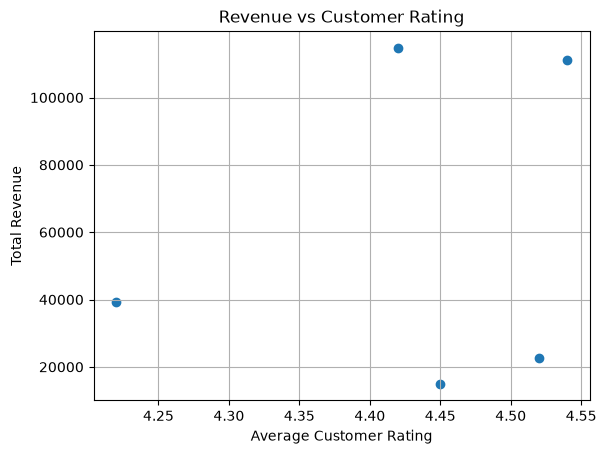

In [36]:
ratings = (df.groupby("Product").agg({
    "Customer_Rating": "mean",
    "Revenue_USD": "sum"
})
)

plt.scatter(ratings["Customer_Rating"],
            ratings["Revenue_USD"])
plt.xlabel("Average Customer Rating")
plt.ylabel("Total Revenue")
plt.title("Revenue vs Customer Rating")
plt.grid()

plt.show()

# Dashboard

Text(0.5, 1.0, 'Revenue vs Customer Rating')

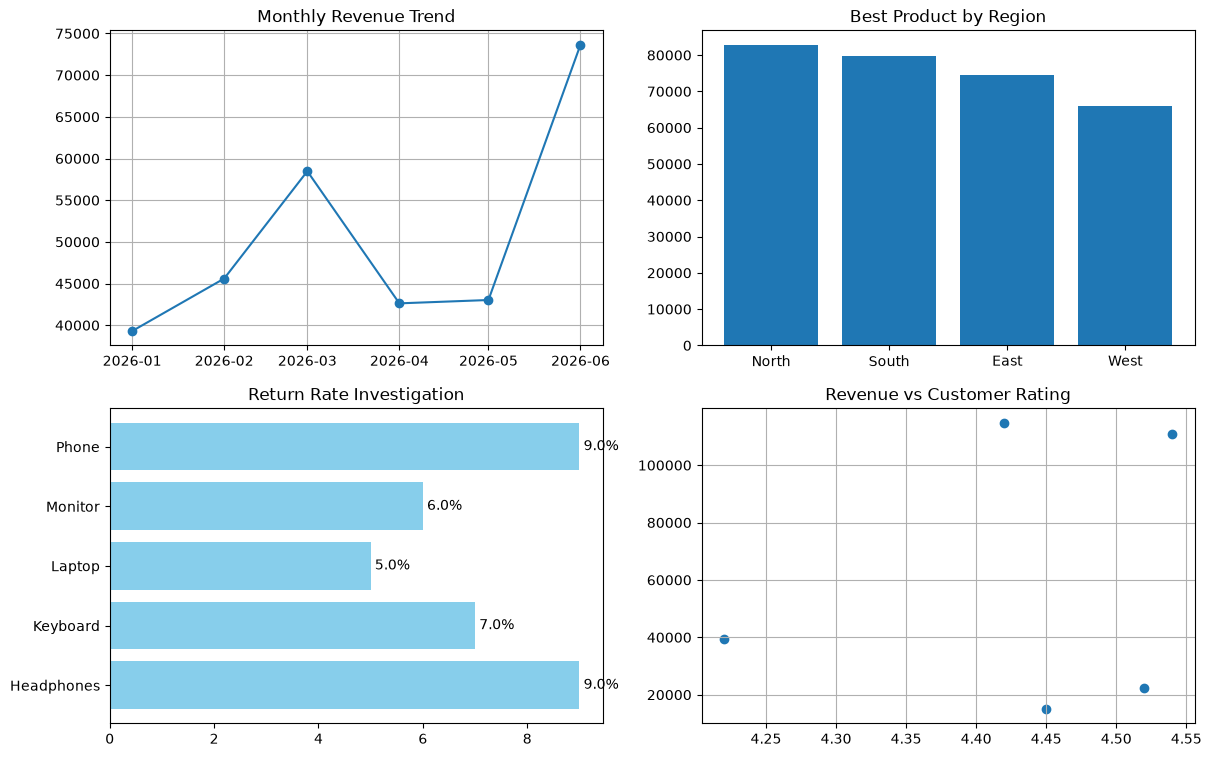

In [38]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

ax[0, 0].plot(monthtly_revenue.index.to_timestamp(),
         monthtly_revenue.values,
         marker='o')
ax[0, 0].grid()
ax[0, 0].set_title("Monthly Revenue Trend")

ax[0, 1].bar(top_product.index,
        top_product["Revenue_USD"])
ax[0, 1].set_title("Best Product by Region")

bar = ax[1, 0].barh(returns.index,
              returns.values,
              color="skyblue")
ax[1, 0].bar_label(bar,
                    fmt="%1.1f%%",
                      padding=3)
ax[1, 0].set_title("Return Rate Investigation")

ax[1, 1].scatter(ratings["Customer_Rating"],
            ratings["Revenue_USD"])
ax[1, 1].grid()
ax[1, 1].set_title("Revenue vs Customer Rating")